# Part 1- Build a co-occurence mattrix

In [2]:
import numpy as np
from collections import defaultdict
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import accuracy_score

import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
import re

In [3]:
# define a large corpus
corpus = [
    "Natural language processing enables computers to understand human language.",
    "Machine learning is a part of artificial intelligence.",
    "Deep learning is a subfield of machine learning.",
    "Text data can be used for sentiment analysis.",
    "Named entity recognition is an information extraction technique.",
    "GloVe stands for Global Vectors for Word Representation.",
    "It captures semantic relationships between words.",
    "Word embeddings are useful for NLP applications.",
    "This tutorial implements GloVe from scratch.",
    "Sentiment analysis determines if a sentence is positive or negative."
]

In [4]:
# clean and tokenize
def preprocess(sentence):
  return re.sub(r"[^a-zA-Z ]", "", sentence).lower().split()

tokenized = [preprocess(sentence) for sentence in corpus]

In [5]:
tokenized

[['natural',
  'language',
  'processing',
  'enables',
  'computers',
  'to',
  'understand',
  'human',
  'language'],
 ['machine',
  'learning',
  'is',
  'a',
  'part',
  'of',
  'artificial',
  'intelligence'],
 ['deep', 'learning', 'is', 'a', 'subfield', 'of', 'machine', 'learning'],
 ['text', 'data', 'can', 'be', 'used', 'for', 'sentiment', 'analysis'],
 ['named',
  'entity',
  'recognition',
  'is',
  'an',
  'information',
  'extraction',
  'technique'],
 ['glove',
  'stands',
  'for',
  'global',
  'vectors',
  'for',
  'word',
  'representation'],
 ['it', 'captures', 'semantic', 'relationships', 'between', 'words'],
 ['word', 'embeddings', 'are', 'useful', 'for', 'nlp', 'applications'],
 ['this', 'tutorial', 'implements', 'glove', 'from', 'scratch'],
 ['sentiment',
  'analysis',
  'determines',
  'if',
  'a',
  'sentence',
  'is',
  'positive',
  'or',
  'negative']]

## Build Vocabulary

In [43]:
import itertools
vocab = sorted(set(itertools.chain(*tokenized)))
vocab_size = len(vocab)

word2id = {word: i for i, word in enumerate(vocab)}
id2word = {i: word for word, i in word2id.items()}

In [44]:
vocab_size

61

In [45]:
id2word

{0: 'a',
 1: 'an',
 2: 'analysis',
 3: 'applications',
 4: 'are',
 5: 'artificial',
 6: 'be',
 7: 'between',
 8: 'can',
 9: 'captures',
 10: 'computers',
 11: 'data',
 12: 'deep',
 13: 'determines',
 14: 'embeddings',
 15: 'enables',
 16: 'entity',
 17: 'extraction',
 18: 'for',
 19: 'from',
 20: 'global',
 21: 'glove',
 22: 'human',
 23: 'if',
 24: 'implements',
 25: 'information',
 26: 'intelligence',
 27: 'is',
 28: 'it',
 29: 'language',
 30: 'learning',
 31: 'machine',
 32: 'named',
 33: 'natural',
 34: 'negative',
 35: 'nlp',
 36: 'of',
 37: 'or',
 38: 'part',
 39: 'positive',
 40: 'processing',
 41: 'recognition',
 42: 'relationships',
 43: 'representation',
 44: 'scratch',
 45: 'semantic',
 46: 'sentence',
 47: 'sentiment',
 48: 'stands',
 49: 'subfield',
 50: 'technique',
 51: 'text',
 52: 'this',
 53: 'to',
 54: 'tutorial',
 55: 'understand',
 56: 'used',
 57: 'useful',
 58: 'vectors',
 59: 'word',
 60: 'words'}

In [46]:
from scipy.sparse import coo
# build co-occurence matrix
def build_cooccurrence_matrix(tokenized, vocab_size, word2id,  window_size=2):
    cooccurrence_matrix = np.zeros((vocab_size, vocab_size), dtype=np.float64)

    for sentence in tokenized:
      sentence_ids = [word2id[word] for word in sentence]
      for idx, word_id in enumerate(sentence_ids):
        start = max(0, idx - window_size)
        end = min( idx + window_size + 1 , len(sentence_ids))

        for context_idx in range(start, end):
          if context_idx != idx:
            context_word_id = sentence_ids[context_idx]
            cooccurrence_matrix[word_id, context_word_id] += 1

    return cooccurrence_matrix


In [47]:
x= build_cooccurrence_matrix(tokenized, vocab_size, word2id, window_size=2)
print(x.shape)

(61, 61)


In [48]:
x

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 1., 0.],
       [0., 0., 0., ..., 1., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]])

In [49]:
# initilaize glove parameters

np.random.seed(42)
embedding_dims=50

w=np.random.rand(vocab_size, embedding_dims) / np.sqrt(embedding_dims)
w_tilde = np.random.rand(vocab_size, embedding_dims) / np.sqrt(embedding_dims)

biases_w = np.zeros(vocab_size)
biases_tilde = np.zeros(vocab_size)

non_zero_indices = np.nonzero(x)

# weighting

def weighting_func(x, x_max=100, alpha=0.75):
  f_x = np.where(x < x_max, (x/x_max) ** alpha, 1.0)
  return f_x

weights = weighting_func(x)

In [50]:
# train glove embeddings

learning_rate = 0.05
num_epocs = 100
for epoch in range(num_epocs):
  total_loss = 0

  for i, j in zip(*non_zero_indices):
    x_ij = x[i,j]
    w_i = w[i]
    w_j = w_tilde[j]
    b_i = biases_w[i]
    b_j = biases_tilde[j]

    weight = weights[i,j]
    inner_product = np.dot(w_i, w_j)
    log_x_ij = np.log(x_ij)

    diff = (inner_product + b_i + b_j - log_x_ij)
    loss = weight * (diff **2)
    total_loss += loss

    grad_w_i = weight * diff * w_j
    grad_w_j = weight * diff * w_i
    grad_b_i = weight * diff
    grad_b_j = weight * diff

    w[i] -= learning_rate * grad_w_i
    w_tilde[j] -= learning_rate * grad_w_j
    biases_w[j] -= learning_rate *grad_b_i
    biases_tilde -= learning_rate *grad_b_j

    if (epoch + 1) % 10 == 0:
      print(f"Epoch {epoch + 1}/{num_epocs}, Loss: {total_loss:.4f}")

Epoch 10/100, Loss: 0.0004
Epoch 10/100, Loss: 0.0008
Epoch 10/100, Loss: 0.0723
Epoch 10/100, Loss: 0.0872
Epoch 10/100, Loss: 0.1056
Epoch 10/100, Loss: 0.1062
Epoch 10/100, Loss: 0.1069
Epoch 10/100, Loss: 0.1072
Epoch 10/100, Loss: 0.1074
Epoch 10/100, Loss: 0.1075
Epoch 10/100, Loss: 0.1077
Epoch 10/100, Loss: 0.1080
Epoch 10/100, Loss: 0.1084
Epoch 10/100, Loss: 0.1087
Epoch 10/100, Loss: 0.1088
Epoch 10/100, Loss: 0.1282
Epoch 10/100, Loss: 0.1283
Epoch 10/100, Loss: 0.1285
Epoch 10/100, Loss: 0.1287
Epoch 10/100, Loss: 0.1287
Epoch 10/100, Loss: 0.1290
Epoch 10/100, Loss: 0.1293
Epoch 10/100, Loss: 0.1294
Epoch 10/100, Loss: 0.1295
Epoch 10/100, Loss: 0.1298
Epoch 10/100, Loss: 0.1300
Epoch 10/100, Loss: 0.1301
Epoch 10/100, Loss: 0.1301
Epoch 10/100, Loss: 0.1304
Epoch 10/100, Loss: 0.1307
Epoch 10/100, Loss: 0.1311
Epoch 10/100, Loss: 0.1314
Epoch 10/100, Loss: 0.1318
Epoch 10/100, Loss: 0.1319
Epoch 10/100, Loss: 0.1321
Epoch 10/100, Loss: 0.1325
Epoch 10/100, Loss: 0.1329
E

In [51]:
embeddings = w + w_tilde

In [53]:
def most_similar(word, embeddings, word2id, id2word, top_n=5):
  idx = word2id[word]
  vec = embeddings[idx].reshape(1, -1)
  sims = cosine_similarity(vec, embeddings)[0]
  top_ids = sims.argsort()[::-1][1:top_n+1]
  return [(id2word[i], sims[i]) for i in top_ids]

print(most_similar("language", embeddings, word2id, id2word))

[('vectors', np.float64(0.8998050451563515)), ('word', np.float64(0.8928783649972466)), ('words', np.float64(0.8875117876523095)), ('artificial', np.float64(0.8848222708139446)), ('sentiment', np.float64(0.8828243966379801))]


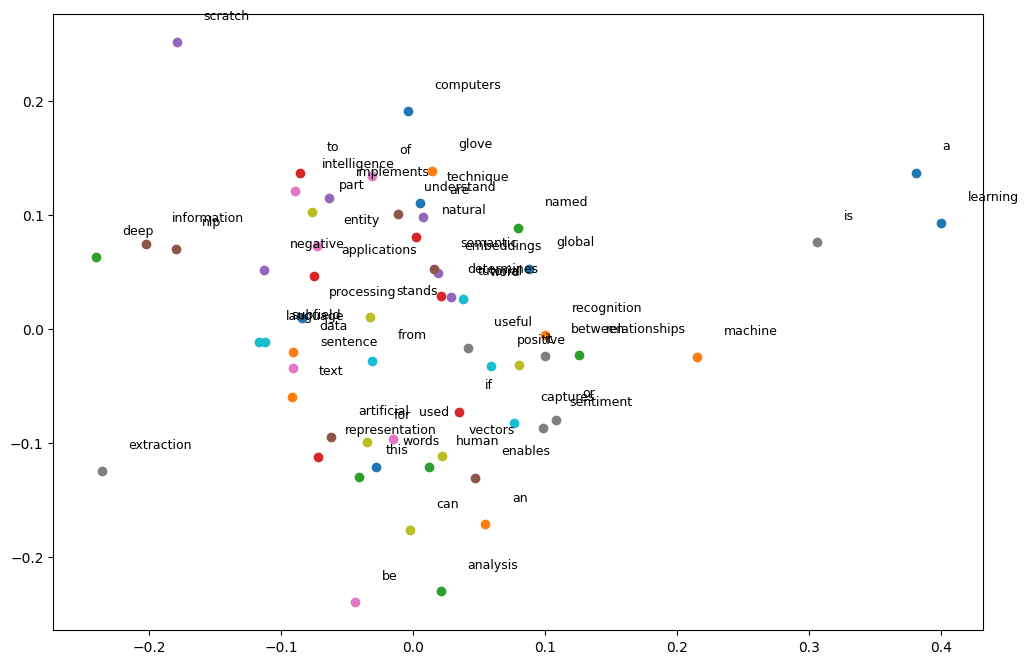

In [55]:
# Visualize embeddings

pca = PCA(n_components=2)
reduced = pca.fit_transform(embeddings)

plt.figure(figsize=(12,8))
for i, word in id2word.items():
  x, y = reduced[i]
  plt.scatter(x, y)
  plt.text(x+0.02, y+0.02, word, fontsize=9)
plt.show()